# Marconi CoastCam image scan (step 1 of the waterline DEM workflow)
csherwood@usgs.gov, 2026-10-21, generated with Claude Opus 5.5

For every timex image during the nanopod record: calibration files from the lookup table, image quality index
(0 = night, 1 = too blurry, 2 = sharp but sunglint, 4 = sharp, high quality), waves and water level interpolated
to the image time, deep-water wave height by reverse shoaling (linear theory), Stockdon et al. (2006) setup and R2
with a starting slope of 0.12, and two camera-pointing checks:
* **horizon**: observed sea horizon vs. the horizon predicted from the calibration EO (offset in px, fitted tilt/roll changes);
* **features** (separate pass): rotation (azimuth, tilt, roll) of quality-4 images, hourly, relative to a reference
  image for that camera/EO, from SIFT matches of static features (Kabsch rotation inside RANSAC). The reference is the
  first quality-4 image with a cleanly detected horizon; its horizon fit shows whether the calibration itself matches.

Changes are listed in `eo_changes.csv` but **not applied**.

Requires: numpy, pandas, scipy, opencv (with SIFT, i.e. OpenCV >= 4.4), pyyaml, matplotlib.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import marconi_scan as ms

# --- config
PROJ = Path(r'F:\crs\proj\2026_wl_dems')
WAVES = PROJ / 'nanopod_waves' / 'sig1000_waves_ALL1.csv'
IMG_ROOT = Path(r'F:\crs\proj\marconi_imagery')
CAL_DIR = IMG_ROOT / 'calibration_parameters'
CAL_TABLE = CAL_DIR / 'calib_parameter_table.csv'
STATIONS = ['caco-03', 'caco-04', 'caco-05']
OUT_DIR = PROJ / 'scan'
FIG_DIR = PROJ / 'fig'
SITE_LAT, SITE_LON = 41.891, -69.963     # Marconi CoastCam, for sun position
BETA0 = 0.12                             # initial foreshore slope for Stockdon
TH = ms.THRESH | {}                      # override thresholds here, e.g. {'blur': 25.}
N_SAMPLE = 120                           # images for the threshold check

OUT_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
SCAN_CSV = OUT_DIR / 'image_scan.csv'

In [2]:
waves = pd.read_csv(WAVES, parse_dates=['time'])
FIRST, LAST = waves.time.iloc[0], waves.time.iloc[-1]
table = ms.read_calib_table(CAL_TABLE)
imgs = ms.list_timex(IMG_ROOT, STATIONS, t0=FIRST, t1=LAST)
imgs['eo_file'] = [ms.calib_files(table, t, s, c)[0] for t, s, c in zip(imgs.time, imgs.station, imgs.camera)]
print(f'nanopod record {FIRST} to {LAST}: {len(imgs)} timex images')
print(imgs.groupby(['station', 'camera', 'eo_file'], dropna=False).time.agg(['count', 'min', 'max']))

nanopod record 2024-12-09 18:00:00 to 2025-03-10 15:00:00: 5508 timex images
                                           count                 min  \
station camera eo_file                                                 
CACO03  c1     CACO03_c1_20241023_EO.yaml    577 2024-12-09 18:00:00   
               CACO03_c1_20250123_EO.yaml    530 2025-01-07 00:00:00   
               NaN                           233 2025-01-04 00:00:00   
        c2     CACO03_c2_20241023_EO.yaml    575 2024-12-09 18:00:00   
               CACO03_c2_20250123_EO.yaml    529 2025-01-07 00:00:00   
               NaN                           233 2025-01-04 00:00:00   
CACO04  c1     CACO04_c1_20250219_EO.yaml   1415 2025-01-24 23:00:00   
        c2     CACO04_c2_20250219_EO.yaml   1416 2025-01-24 23:00:00   

                                                          max  
station camera eo_file                                         
CACO03  c1     CACO03_c1_20241023_EO.yaml 2025-01-03 23:30:00  
          

## Threshold check
Quality metrics on a random sample of images (no pointing). Check the scatter and the example images, then
adjust `TH` in the config cell before the full scan.

quality
0    43
1    28
2     5
4    44
dtype: int64


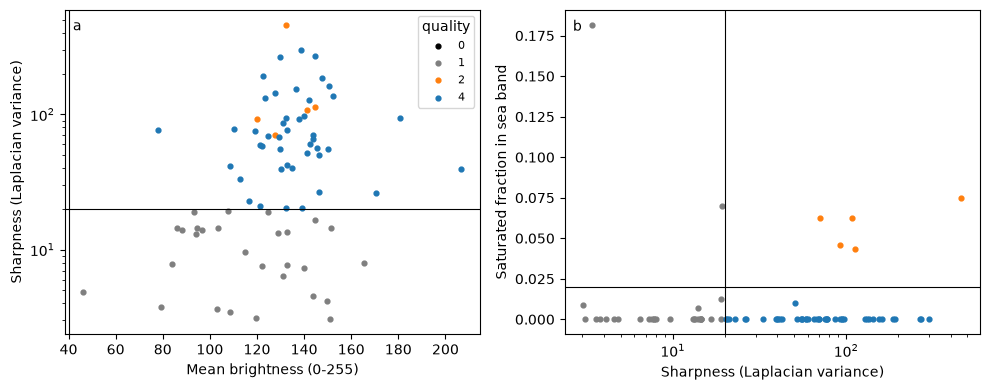

In [3]:
smp = imgs.dropna(subset=['eo_file']).sample(min(N_SAMPLE, imgs.eo_file.notna().sum()), random_state=1).sort_values('time')
smp['sun_el'], smp['sun_az'] = ms.sun_position(smp.time, SITE_LAT, SITE_LON)
rows = []
for _, r in smp.iterrows():
    eo_file, io_file = ms.calib_files(table, r.time, r.station, r.camera)
    io, eo = ms.read_yaml(CAL_DIR / io_file), ms.read_yaml(CAL_DIR / eo_file)
    rows.append(ms.scan_image(r.path, io, eo, r.sun_el, r.sun_az, TH)[0] | {'path': r.path, 'camera': r.camera})
smp_m = pd.DataFrame(rows)
print(smp_m.groupby('quality').size())

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for q, c in zip([0, 1, 2, 4], ['k', 'tab:gray', 'tab:orange', 'tab:blue']):
    s = smp_m[smp_m.quality == q]
    ax[0].scatter(s.brightness, s.sharpness, s=12, c=c, label=str(q))
    ax[1].scatter(s.sharpness, s.glint_frac, s=12, c=c, label=str(q))
ax[0].axvline(TH['dark'], c='k', lw=0.8); ax[0].axhline(TH['blur'], c='k', lw=0.8)
ax[1].axvline(TH['blur'], c='k', lw=0.8); ax[1].axhline(TH['glint'], c='k', lw=0.8)
ax[0].set_xlabel('Mean brightness (0-255)'); ax[0].set_ylabel('Sharpness (Laplacian variance)'); ax[0].set_yscale('log')
ax[1].set_xlabel('Sharpness (Laplacian variance)'); ax[1].set_ylabel('Saturated fraction in sea band'); ax[1].set_xscale('log')
ax[0].legend(title='quality', fontsize=8)
for a, l in zip(ax, 'ab'):
    a.text(0.02, 0.97, l, transform=a.transAxes, va='top')
fig.tight_layout()
fig.savefig(FIG_DIR / 'scan_thresholds.png', dpi=150)

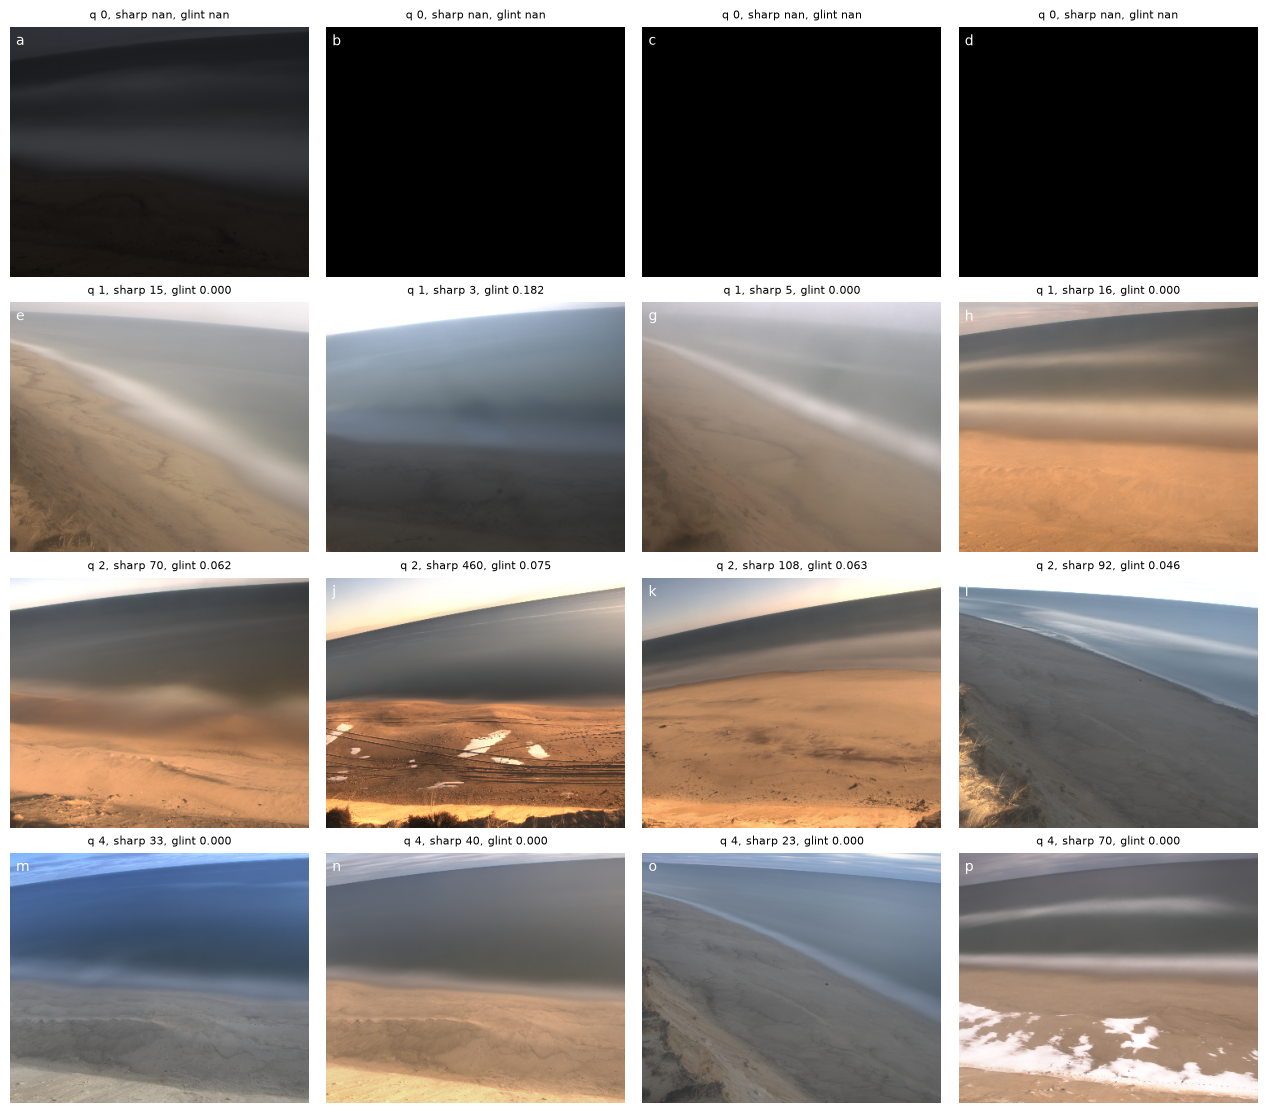

In [4]:
# up to 4 examples of each quality class
ex = smp_m.groupby('quality').head(4).sort_values('quality').reset_index(drop=True)
nc = 4
nr = int(np.ceil(len(ex) / nc))
fig, ax = plt.subplots(nr, nc, figsize=(3.2 * nc, 2.8 * nr), squeeze=False)
for i, a in enumerate(ax.flat):
    a.axis('off')
    if i < len(ex):
        im = cv2.cvtColor(cv2.resize(cv2.imread(ex.path[i]), None, fx=0.15, fy=0.15), cv2.COLOR_BGR2RGB)
        a.imshow(im)
        a.set_title(f'q {ex.quality[i]:.0f}, sharp {ex.sharpness[i]:.0f}, glint {ex.glint_frac[i]:.3f}', fontsize=8)
        a.text(0.02, 0.97, chr(97 + i), transform=a.transAxes, va='top', color='w')
fig.tight_layout()
fig.savefig(FIG_DIR / 'scan_quality_examples.jpg', dpi=120)

## Full scan
Writes `image_scan.csv` in chunks and resumes where it stopped if rerun (an existing CSV is simply reloaded).

In [5]:
scan = ms.scan(imgs.drop(columns='eo_file'), waves, table, CAL_DIR, SCAN_CSV, SITE_LAT, SITE_LON, beta=BETA0, th=TH)
print(scan.groupby(['camera', 'quality']).size().unstack())

quality  -1.0    0.0    1.0    2.0     4.0
camera                                    
c1        1.0  928.0  591.0  165.0   837.0
c2        NaN  925.0  391.0   43.0  1161.0


## Pointing pass
Rotation of quality-4 images relative to a reference image, at most one per `TH['pt_every']` per camera
(about 1 s each). Rewrites the pointing columns of `image_scan.csv`; rerun with different settings at will.

In [6]:
scan = ms.pointing_pass(scan, CAL_DIR, TH)
scan.to_csv(SCAN_CSV, index=False, float_format='%.4g')
print(scan.loc[scan.is_ref == True, ['camera', 'eo_file', 'time', 'hz_offset', 'hz_dtilt', 'hz_droll']])

c1 CACO03_c1_20241023_EO.yaml: reference 2024-12-13 12:00:00, horizon fit at reference dtilt +2.19, droll -0.03 (deg); 58 images checked
c1 CACO03_c1_20250123_EO.yaml: reference 2025-01-08 12:30:00, horizon fit at reference dtilt +1.60, droll +0.39 (deg); 101 images checked
c1 CACO04_c1_20250219_EO.yaml: reference 2025-01-25 13:00:00, horizon fit at reference dtilt +1.63, droll +0.54 (deg); 330 images checked
c2 CACO03_c2_20241023_EO.yaml: reference 2024-12-09 18:00:00, horizon fit at reference dtilt +0.33, droll +0.14 (deg); 116 images checked
c2 CACO03_c2_20250123_EO.yaml: reference 2025-01-08 12:30:00, horizon fit at reference dtilt +0.49, droll -0.50 (deg); 118 images checked
c2 CACO04_c2_20250219_EO.yaml: reference 2025-01-25 12:00:00, horizon fit at reference dtilt +0.32, droll +0.21 (deg); 417 images checked
     camera                     eo_file                time  hz_offset  \
1        c2  CACO03_c2_20241023_EO.yaml 2024-12-09 18:00:00      21.47   
215      c1  CACO03_c1_20

## Running list of camera-pointing changes (not applied)
Daily medians of the feature-based changes, grouped into runs of constant pointing. `d_az`, `d_tilt`, `d_roll` are
changes since the reference image, so the first run is ~0 and `moved` flags later runs that differ by more than `tol`.
`azimuth`, `tilt`, `roll` are the calibration angles plus that change (assumes the reference matched the calibration).
`hz_dtilt`, `hz_droll` are the horizon fit against the calibration: if they are well away from 0 in the first run,
the calibration EO itself is off (tilt is reliable from the horizon; roll is partly confounded with azimuth).

In [7]:
chg = ms.eo_changes(scan, CAL_DIR, tol=0.15, min_inliers=TH['pt_min_inliers'])
chg.to_csv(OUT_DIR / 'eo_changes.csv', index=False, float_format='%.4f')
chg

,camera,eo_file,io_file,first_day,last_day,n_days,d_az,d_tilt,d_roll,hz_dtilt,hz_droll,azimuth,tilt,roll,moved
0,c1,CACO03_c1_20241023_EO.yaml,CACO03_c1_20240801_IO.yaml,2024-12-13,2024-12-15,3,-0.004726,-0.020104,0.000179,2.18900,-0.059520,60.035274,67.831896,-5.420821,False
1,c1,CACO03_c1_20250123_EO.yaml,CACO03_c1_20240801_IO.yaml,2025-01-08,2025-01-08,1,0.032624,-0.000552,-0.004192,1.59200,0.313800,72.602624,71.599448,-6.674192,False
2,c1,CACO04_c1_20250219_EO.yaml,CACO03_c1_20240801_IO.yaml,2025-01-25,2025-01-28,2,-0.002562,0.001640,-0.015756,1.61700,0.522375,57.270738,71.592040,-10.778656,False
3,c2,CACO03_c2_20241023_EO.yaml,CACO03_c2_20240801_IO.yaml,2024-12-09,2024-12-16,3,0.013347,-0.001781,-0.011269,0.32250,0.132600,22.981347,73.646219,4.598831,False
4,c2,CACO03_c2_20241023_EO.yaml,CACO03_c2_20240801_IO.yaml,2024-12-24,2024-12-24,1,-0.007587,-0.064227,-0.174451,0.32340,0.131700,22.960413,73.583773,4.435649,True
5,c2,CACO03_c2_20250123_EO.yaml,CACO03_c2_20240801_IO.yaml,2025-01-08,2025-01-09,2,0.038448,-0.002452,0.021289,0.52285,-0.511425,36.413448,73.317548,4.635289,False
6,c2,CACO04_c2_20250219_EO.yaml,CACO03_c2_20240801_IO.yaml,2025-01-25,2025-02-08,7,-0.012954,0.025351,-0.018723,0.33730,0.195650,20.831446,74.991551,3.938777,False
7,c2,CACO04_c2_20250219_EO.yaml,CACO03_c2_20240801_IO.yaml,2025-02-15,2025-02-15,1,-0.110251,-0.028028,-0.250395,0.36160,0.182800,20.734149,74.938172,3.707105,True


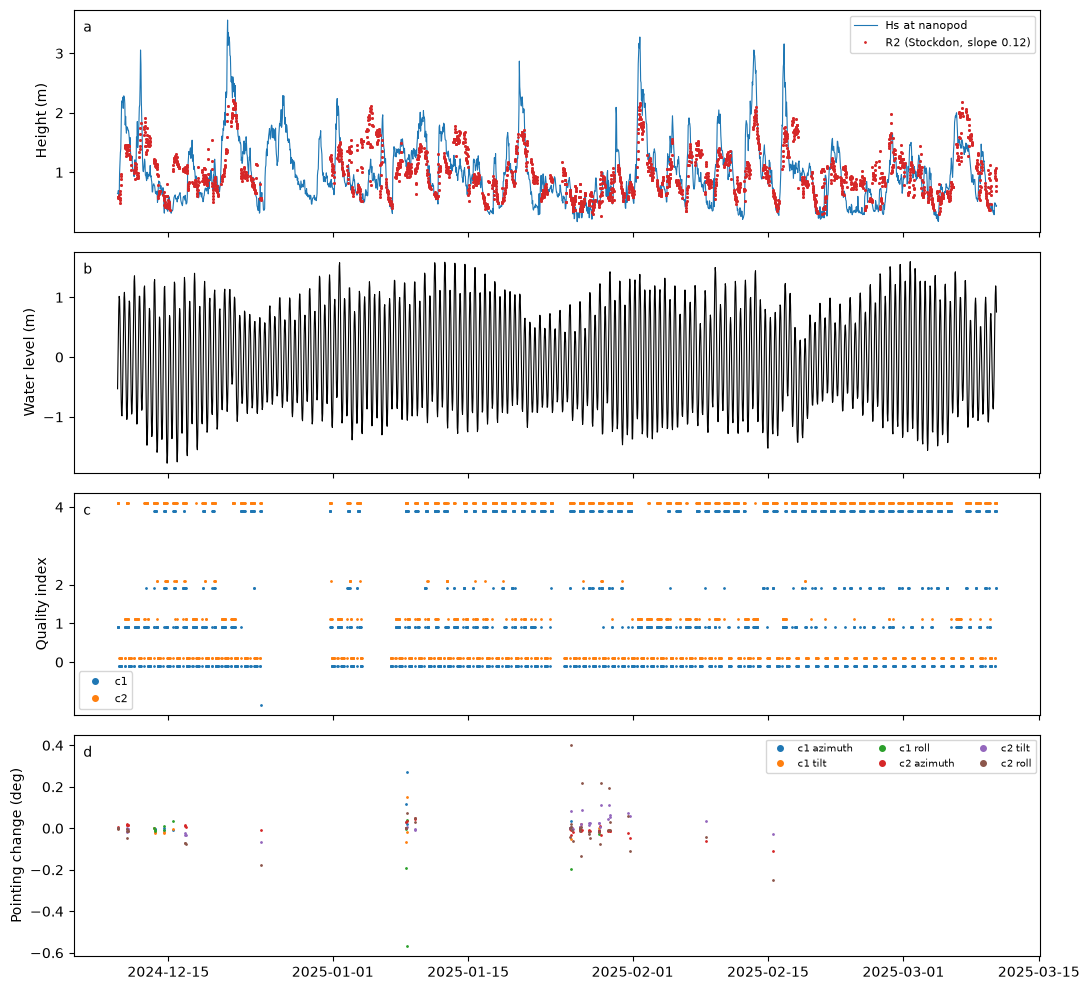

In [8]:
fig, ax = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
ax[0].plot(waves.time, waves.wh_4061, c='tab:blue', lw=0.8, label='Hs at nanopod')
ax[0].plot(scan.time, scan.R2, '.', c='tab:red', ms=2, label=f'R2 (Stockdon, slope {BETA0})')
ax[0].set_ylabel('Height (m)'); ax[0].legend(fontsize=8)
ax[1].plot(waves.time, waves.water_level, c='k', lw=0.8)
ax[1].set_ylabel('Water level (m)')
for cam, off in [('c1', -0.1), ('c2', 0.1)]:
    s = scan[scan.camera == cam]
    ax[2].plot(s.time, s.quality + off, '.', ms=2, label=cam)
    ax[3].plot(s.time, s.d_az, '.', ms=2, label=f'{cam} azimuth')
    ax[3].plot(s.time, s.d_tilt, '.', ms=2, label=f'{cam} tilt')
    ax[3].plot(s.time, s.d_roll, '.', ms=2, label=f'{cam} roll')
ax[2].set_yticks([0, 1, 2, 4]); ax[2].set_ylabel('Quality index'); ax[2].legend(fontsize=8, markerscale=4)
ax[3].set_ylabel('Pointing change (deg)'); ax[3].legend(fontsize=7, ncol=3, markerscale=4)
for a, l in zip(ax, 'abcd'):
    a.text(0.01, 0.95, l, transform=a.transAxes, va='top')
fig.tight_layout()
fig.savefig(FIG_DIR / 'scan_timeseries.png', dpi=150)

In [12]:
print(s.columns)

Index(['time', 'quality', 'wh_4061', 'wp_peak', 'R2', 'path', 'station',
       'camera', 'wvdir', 'water_level', 'water_depth', 'H0', 'setup',
       'brightness', 'sharpness', 'glint_frac', 'glint_view', 'sun_el',
       'sun_az', 'hz_offset', 'hz_strength', 'hz_dtilt', 'hz_droll',
       'hz_fit_px', 'is_ref', 'pt_ref', 'pt_inliers', 'd_az', 'd_tilt',
       'd_roll', 'eo_file', 'io_file'],
      dtype='str')


## Before/after check of a pointing change
Set the camera and the time of the suspected change (by default the start of the first run of `chg` flagged as moved).
Shows the last quality-4 image before that time and the first one after it, with the sea horizon predicted from the
calibration EO (yellow, dashed) and from the horizon fit to that image (cyan). Panel c is a red/cyan overlay of the zoom
box (before in red, after in cyan): static features that are doubled or color-fringed show a shift. Panel d is the
pointing change for this camera around that time, to tell a step (knock, re-aim) from a gradual drift.

In [13]:
r

time                                         2024-12-24 12:30:00
quality                                                      4.0
wh_4061                                                   0.6921
wp_peak                                                     4.98
R2                                                         0.554
path           F:\crs\proj\marconi_imagery\caco-03\c2\2024\35...
station                                                   CACO03
camera                                                        c2
wvdir                                                      147.0
water_level                                               0.4263
water_depth                                                21.43
H0                                                         0.696
setup                                                      0.218
brightness                                                 143.5
sharpness                                                  263.7
glint_frac               

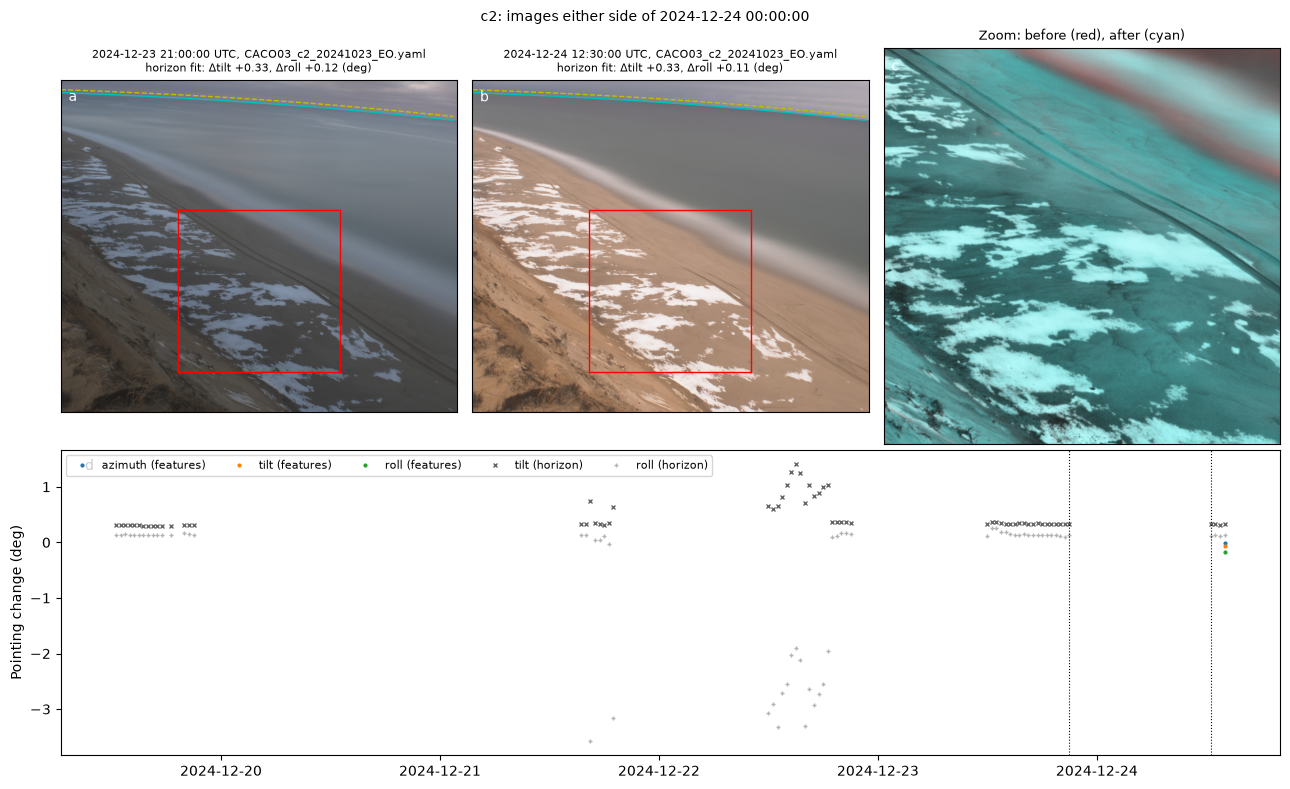

In [9]:
CAMERA, T_CHANGE = (chg[chg.moved].camera.iloc[0], pd.Timestamp(chg[chg.moved].first_day.iloc[0])) if chg.moved.any() \
    else ('c1', pd.Timestamp('2025-02-01'))      # set by hand when nothing is flagged
ZOOM = (1224, 1300, 500)                        # zoom box: center column, center row, half-width (px)
DAYS = 5                                        # days either side shown in panel d

s = scan[(scan.camera == CAMERA) & (scan.quality == 4)]
b, a = s[s.time < T_CHANGE].iloc[-1], s[s.time >= T_CHANGE].iloc[0]
fig, ax = plt.subplot_mosaic('abc;ddd', figsize=(13, 8), height_ratios=[1.3, 1])
for k, r in zip('ab', [b, a]):
    io, eo = ms.read_yaml(CAL_DIR / r.io_file), ms.read_yaml(CAL_DIR / r.eo_file)
    cols = np.arange(0, io['NU'], 25)
    ax[k].imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB))
    ax[k].plot(cols, ms.horizon_rows(io, eo, cols), '--', c='y', lw=1)
    ax[k].plot(cols, ms.horizon_rows(io, dict(eo, tilt=eo['tilt'] + r.hz_dtilt, roll=eo['roll'] + r.hz_droll), cols), c='c', lw=1)
    ax[k].add_patch(plt.Rectangle((ZOOM[0] - ZOOM[2], ZOOM[1] - ZOOM[2]), 2 * ZOOM[2], 2 * ZOOM[2], fill=False, ec='r', lw=1))
    ax[k].set_title(f'{r.time} UTC, {r.eo_file}\nhorizon fit: $\\Delta$tilt {r.hz_dtilt:+.2f}, $\\Delta$roll {r.hz_droll:+.2f} (deg)', fontsize=8)
g = [cv2.imread(r.path, cv2.IMREAD_GRAYSCALE)[ZOOM[1] - ZOOM[2]:ZOOM[1] + ZOOM[2], ZOOM[0] - ZOOM[2]:ZOOM[0] + ZOOM[2]] for r in (b, a)]
g = [cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(x) for x in g]
ax['c'].imshow(np.dstack([g[0], g[1], g[1]]))
ax['c'].set_title('Zoom: before (red), after (cyan)', fontsize=9)
for k in 'abc':
    ax[k].set_xticks([]); ax[k].set_yticks([])
w = scan[(scan.camera == CAMERA) & (scan.quality == 4) & (abs(scan.time - T_CHANGE) < pd.Timedelta(days=DAYS))]
for v, lab in [('d_az', 'azimuth'), ('d_tilt', 'tilt'), ('d_roll', 'roll')]:
    ax['d'].plot(w.time, w[v], '.', ms=4, label=f'{lab} (features)')
ax['d'].plot(w.time, w.hz_dtilt, 'x', ms=3, c='0.4', label='tilt (horizon)')
ax['d'].plot(w.time, w.hz_droll, '+', ms=3, c='0.7', label='roll (horizon)')
ax['d'].axvline(b.time, c='k', lw=0.8, ls=':'); ax['d'].axvline(a.time, c='k', lw=0.8, ls=':')
ax['d'].set_ylabel('Pointing change (deg)'); ax['d'].legend(fontsize=8, ncol=5)
for k in 'abcd':
    ax[k].text(0.02, 0.97, k, transform=ax[k].transAxes, va='top', color='w' if k != 'd' else 'k')
fig.suptitle(f'{CAMERA}: images either side of {T_CHANGE}', fontsize=10)
fig.tight_layout()
fig.savefig(FIG_DIR / f'pointing_change_{CAMERA}_{T_CHANGE:%Y%m%d_%H%M}.jpg', dpi=150)